# Figure S9 — PDB-disorder-monomer benchmark: all four rankings in one figure

Panels A–D (`figure_S09A–D.ipynb`) stacked into one figure with panel letters: the top 40 CAID3 disorder predictors ranked by (A) AUC, (B) APS, (C) Fmax and (D) MCC at each method's Fmax threshold, on the PDB-disorder-monomer benchmark. metapredict V1, V2 and V3 are coloured wherever they fall within the top 40.

**How it is made.** Same labels, scoring and drawing as the panel notebooks (see `figure_S09A.ipynb` for the benchmark definition); the predictors are scored once and each panel is drawn with the same `metric_panel` call at the same size.

**Output:** `figures/figure_S09.pdf`

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

from caid3_panels import load_predictions, metric_panel, print_metapredict_ranks, rank_predictors
from figtools import apply_style, label_panels, require_metapredict_3_1, save_panel, shared_data_path

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATASET = 'PDB-disorder-monomer'
TOP_N = 40

# (attribute, y-axis label) for panels A-D, in panel order
METRICS = [('auc', 'AUC'), ('aps', 'APS'), ('fmax', 'Fmax'), ('mcc', 'MCC')]
PANEL_LETTERS = 'ABCD'
# each panel is drawn at the size of the single-panel notebooks (inches)
PANEL_WIDTH_IN = 6.5
PANEL_HEIGHT_IN = 2.2

metapredict 3.1.0+7.g7dcf52c.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
# per-residue monomer labels: 1 disordered, 0 ordered, -1 excluded (sequence unused)
with open(shared_data_path('pdb_cache', 'monomer_labels.json')) as fh:
    reference = {tid: ('', np.asarray(labels, dtype=np.int8)) for tid, labels in json.load(fh).items()}

n_disordered = sum(int((lab == 1).sum()) for _, lab in reference.values())
n_ordered = sum(int((lab == 0).sum()) for _, lab in reference.values())
n_targets = sum(1 for _, lab in reference.values() if (lab >= 0).any())
print(f'{DATASET}: {n_ordered} ordered + {n_disordered} disordered residues over {n_targets} targets '
      f'({n_ordered / n_disordered:.1f} : 1)')

ranking = rank_predictors(reference, load_predictions(), dataset=DATASET)
print_metapredict_ranks(ranking)

PDB-disorder-monomer: 32904 ordered + 3807 disordered residues over 134 targets (8.6 : 1)


AUC   V1 0.693 (rank 43/66), V2 0.759 (rank 19/66), V3 0.791 (rank 11/66)
APS   V1 0.206 (rank 42/66), V2 0.255 (rank 21/66), V3 0.299 (rank 12/66)
FMAX  V1 0.284 (rank 46/66), V2 0.359 (rank 18/66), V3 0.412 (rank 9/66)
MCC   V1 0.185 (rank 46/66), V2 0.275 (rank 20/66), V3 0.340 (rank 10/66)


Wrote figures/figure_S09.pdf


PosixPath('figures/figure_S09.pdf')

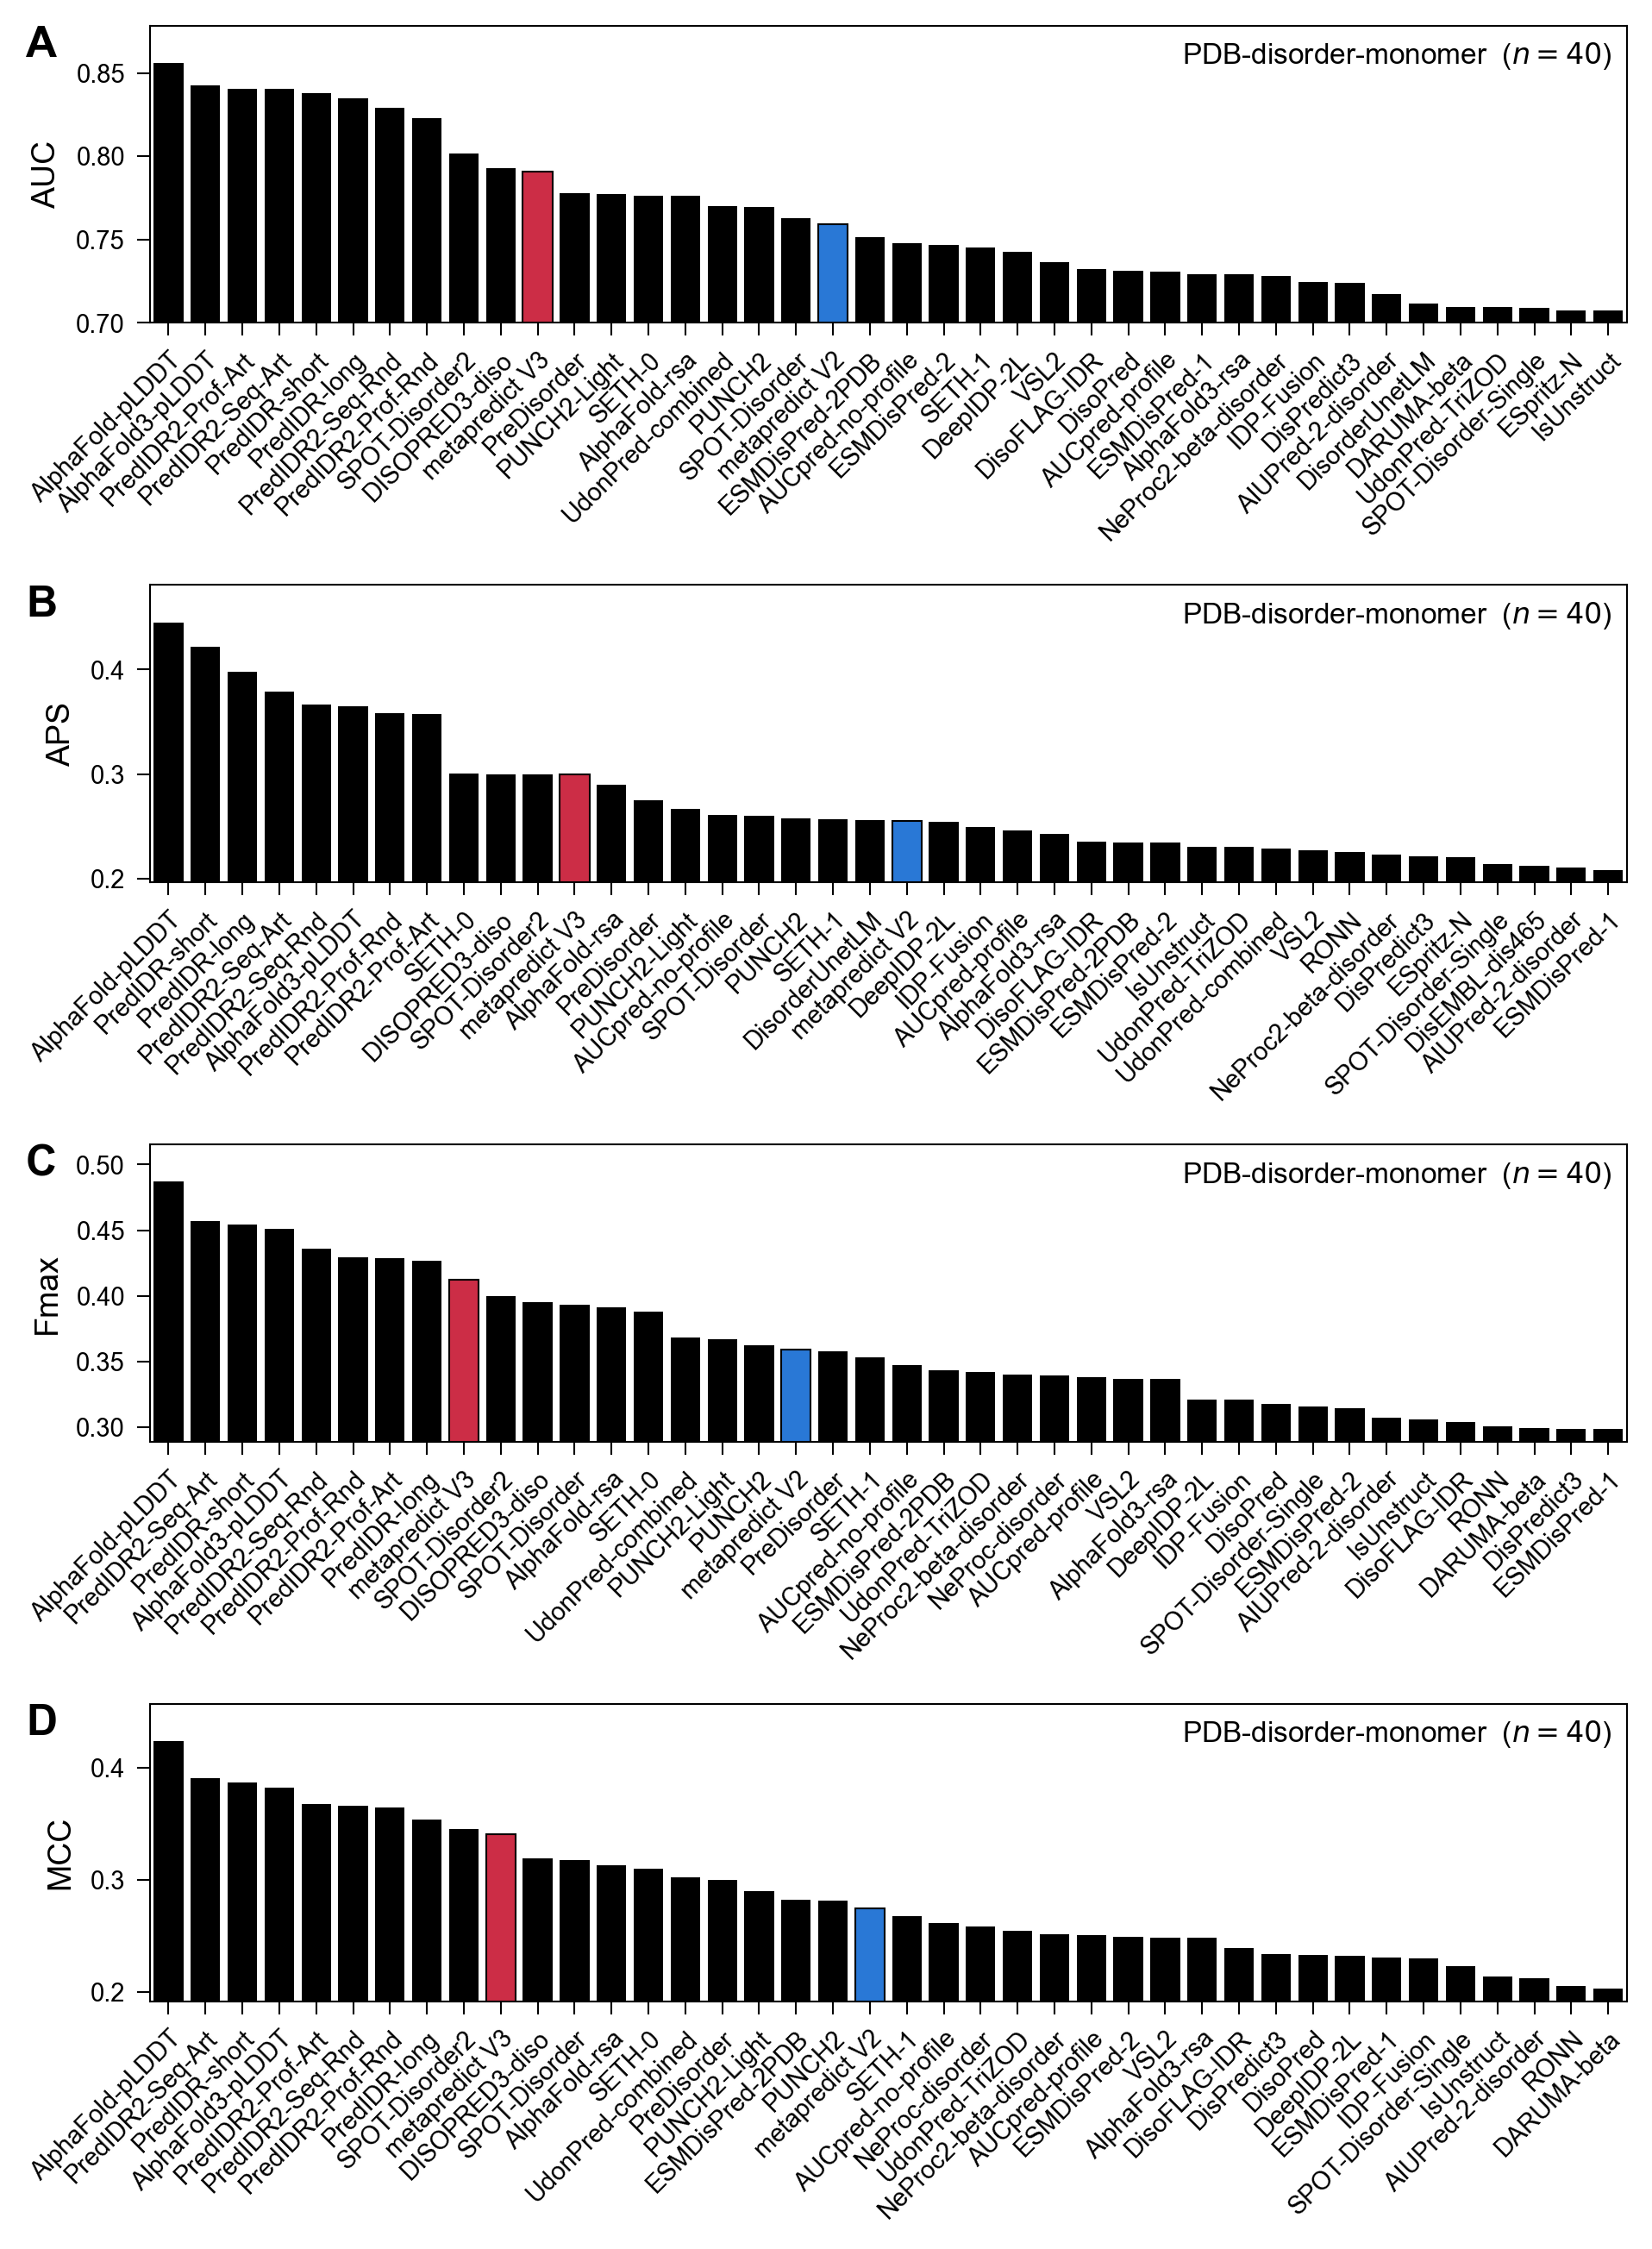

In [3]:
fig, axes = plt.subplots(len(METRICS), 1, figsize=(PANEL_WIDTH_IN, PANEL_HEIGHT_IN * len(METRICS)), dpi=150)
for ax, (attr, ylabel) in zip(axes, METRICS):
    metric_panel(ax, ranking, attr, ylabel, DATASET, top_n=TOP_N)
plt.tight_layout()
label_panels(fig, axes, PANEL_LETTERS)
save_panel(fig, 'figure_S09')